# CN1-DA1 Notebook: Analysis of LFP evoked responses

**In the "data" folder, you will find 16 files**

The data were recorded during two differents sessions

The files **RAT24-012-01_electrode_x** contains data from simulteanous recordings of local field potentials (like sEEG) from 8 differents electrodes placed in the layer 4 of the somatosensory cortex of the rat during tactile stimulation applied on the digit tips of the digit 2,3,4 and 5.

the files RAT24-008-01_electrode_x contains data from another recording session.

The electrode are placed in line in the putative axis of the somatotopy.

 Each file contains two arrays: "LFP" and "StimCond". See the code below to load the array variables from the files, with a loop to go through all files. We recommend you to do the exercise for a file, then to automatize for all files.

The LFP array contains the recording of local field potential (LFP) with a sampling rate of 1 ms.

The StimCond array has 2 columns: the first for the time stamps to trigger a stimulus, whose onset is 50 ms later; the second for the category of stimulus (in fact, which digit of the rat fore paw is stimulated, from 2 to 5, meaning 4 categories).

The goal of this analysis is to test whether the digit stimulation affects the neuronal response as measured by the LFP. To do so, you will extract the LFP signal around the stimulus onset with an epoch starting **150 ms before and stopping 150 ms after**. 
You will then calculate the average response over all stimuli / epochs, as well as the average response for each of the 4 stimulus conditions. From the average responses, the quantities of interest are :
- the minimum of the curve after the stimulus onset during a window of 50 ms
- the corresponding latency, 
- the Area Under the Curve during the Evoked period.

**You will produce two figures to represent these results:**

* **Figure 1 for session "RAT24-008-02_electrode_9" with**
    - a line plot of the responses for all epochs (i.e. all categories together) as well as the global average over all stimuli;
    - a line plot of the 4 curves that compare the average responses of the 4 categories, with a marker to indicate the minimum of the response after the stimulus onset;
    - note that the x-axis is time for both plots above should be going from 150 ms before the stimulus onset to 150 ms after.
    - a boxplot of the minima for each epoch as a function of the stimulated digit (with each category on the x-axis);
    - a box plot of the Area under the curve (AUC)  during the period of the evoked period (it's up to you to search for the function and tell why this measure if relevant)

* **Figure 2 for all 16 files from the 2 sessions with**
    - 2 line plots that displays a line for each electrode from a session with the response minimum as a function of the stimulated digit (one curve per electrode); (one plot for each session with electrodes 9 to 16)
    - a similar plot for the response latencies and the AUC 
    - use the same color for each session in the two plots and add a legend.

**How do you interpret the results? the differences between the measures from different electrodes of a given session ?  Write your interpretation in a few lines of text in a markdown cell at the end of your notebook.**

You can make additional figures to support your interpretation.

In [ ]:
import numpy as np
from glob import glob
import matplotlib.pyplot as plt
import os


filenames = os.listdir()
print(filenames)

'D:\\DATA\\Projets\\M1_CN_DA_Homework_Final_Exam_2026_MG_NC\\data_hw'

In [ ]:
# check arrays in all files
for filename in filenames:
    LFP = np.load(filename, allow_pickle=True)["LFP"]
    StimCond = np.load(filename, allow_pickle=True)["StimCond"]
    print(filename, LFP.shape, StimCond.shape)

RAT24-008-02.mat_electrode_10.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_11.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_12.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_13.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_14.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_15.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_16.npz (1007949, 1) (600, 2)
RAT24-008-02.mat_electrode_9.npz (1007949, 1) (600, 2)
RAT24-012-01.mat_electrode_10.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_11.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_12.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_13.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_14.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_15.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_16.npz (1358843, 1) (1200, 2)
RAT24-012-01.mat_electrode_9.npz (1358843, 1) (1200, 2)


In [28]:
StimCond

array([[   2127,       2],
       [   3250,       4],
       [   4372,       3],
       ...,
       [1346718,       4],
       [1347842,       4],
       [1348966,       4]], shape=(1200, 2))

Below are a few plots to illustrate the data for the last file.

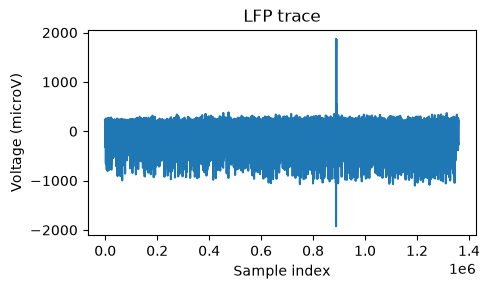

In [29]:
plt.figure(figsize=(5,3))
plt.plot(LFP)
plt.xlabel('Sample index')
plt.ylabel('Voltage (microV)')
plt.title('LFP trace')
plt.tight_layout()

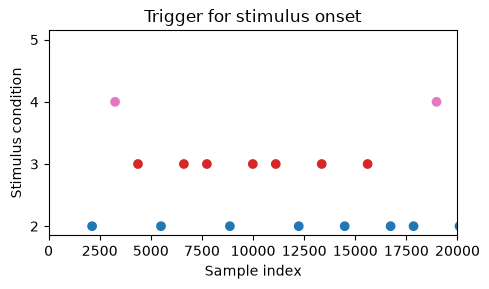

In [ ]:
plt.figure(figsize=(5,4))

plt.scatter(StimCond[:,0], StimCond[:,1], c=StimCond[:,1], cmap='tab10')
plt.xlabel('Sample index')
plt.ylabel('Stimulus condition')
plt.title('Trigger for stimulus onset')
plt.xlim([0, 20000])
plt.yticks(range(2,6))
plt.tight_layout()